# Objective 1 - How pairwise (DeFiTail-style) detection degrades as N grows
**Data**: `data/processed/paths.csv` from `build_dataset.ipynb` - pairwise data paths for 750+ real exploits (DeFiHackLabs),
each tagged with its contract count N and bucket (2, 3-5, 6-10, 11+).

**Model**: DeFiTail's dual branch - a BERT encoder over each opcode path + a 2-layer GCN over the path/opcode heterogeneous
graph (PPMI opcode-opcode edges, TF-IDF path-opcode edges), fused as `lam * p_gcn + (1 - lam) * p_bert`. Two binary tasks:
access control, flash loan.

**Protocol**: 5-fold cross-validation **by incident** (no incident in both train and test), stratified by bucket and label,
repeated over 3 seeds. Every incident is tested once per seed. Metrics per bucket at path level and incident level
(incident flagged if any of its paths is), reported as mean +- sd over seeds.

**Deviations from the paper (CPU-only machine, documented)**: smaller BERT (2 layers, 128 hidden, 256 tokens head+tail) trained
from scratch; one shared encoder with two task heads; stack-only opcodes removed from paths; dataset is DeFiHackLabs, not
DeFiTail's unreleased REKT paths, so numbers are not directly comparable to 98.39% / 97.43%.

In [1]:
import json, time, sys
from pathlib import Path
import numpy as np, pandas as pd, scipy.sparse as sp, torch, torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import BertConfig, BertModel
from torch_geometric.nn import GCNConv
from sklearn.metrics import roc_auc_score
from IPython.display import Image, display


In [2]:
ROOT = Path.cwd()
PROCESSED, RESULTS = ROOT / "data" / "processed", ROOT / "results"
TASKS = ["access_control", "flash_loan"]
BUCKETS = ["2", "3-5", "6-10", "11+"]
CFG = dict(max_len=256, hidden=128, layers=2, heads=4, bert_epochs=4, bert_lr=3e-4, batch=32,
           gcn_hidden=200, gcn_epochs=100, gcn_lr=1e-2, lam=0.5, folds=5, seeds=[0, 1, 2], window=20)
torch.set_num_threads(8)

In [3]:
def load_paths(name="paths.csv"):
    df = pd.read_csv(PROCESSED / name, dtype={"bucket": str})
    df = df[df.opcodes.notna() & (df.opcodes.str.len() > 0)].reset_index(drop=True)
    return df


# ---------- encoding ----------
def head_tail(tokens, n):
    return tokens if len(tokens) <= n else tokens[: n // 2] + tokens[-(n - n // 2):]


def encode(df, vocab, max_len):
    X = np.zeros((len(df), max_len), dtype=np.int64)
    for i, s in enumerate(df.opcodes.str.split()):
        ids = [1] + [vocab.get(t, 2) for t in head_tail(s, max_len - 1)]   # 0 pad, 1 cls, 2 unk
        X[i, :len(ids)] = ids
    return torch.from_numpy(X)


# ---------- heterogeneous path/opcode graph (BertGCN / TextGCN style, sparse) ----------
def build_graph(df, vocab, window):
    nP, nV = len(df), len(vocab)
    rows, cols, wr, wc = [], [], [], []
    w_id = 0
    for i, s in enumerate(df.opcodes.str.split()):
        ids = [vocab[t] - 3 for t in s if t in vocab]
        rows += [i] * len(ids); cols += ids
        for st in range(0, max(1, len(ids) - window + 1), window // 2):   # windows with 50% overlap
            for t in set(ids[st:st + window]): wr.append(w_id); wc.append(t)
            w_id += 1
    tf = sp.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(nP, nV))
    W = sp.csr_matrix((np.ones(len(wr)), (wr, wc)), shape=(w_id, nV))
    co = (W.T @ W).toarray(); np.fill_diagonal(co, 0)
    p = np.asarray(W.sum(0)).ravel() / w_id
    with np.errstate(divide="ignore", invalid="ignore"):
        ppmi = np.nan_to_num(np.maximum(np.log((co / w_id) / np.outer(p, p)), 0), posinf=0, neginf=0)
    idf = np.log((1 + nP) / (1 + np.asarray((tf > 0).sum(0)).ravel())) + 1
    tfidf = sp.csr_matrix(sp.diags(1 / np.maximum(np.asarray(tf.sum(1)).ravel(), 1)) @ tf @ sp.diags(idf))
    A = sp.bmat([[None, tfidf], [tfidf.T, sp.csr_matrix(ppmi)]], format="coo")
    A = (A + sp.eye(nP + nV)).tocoo()
    return torch.tensor(np.vstack([A.row, A.col]), dtype=torch.long), torch.tensor(A.data, dtype=torch.float)


# ---------- models ----------
class BertBranch(nn.Module):
    def __init__(self, vocab, c):
        super().__init__()
        cfg = BertConfig(vocab_size=vocab, hidden_size=c["hidden"], num_hidden_layers=c["layers"],
                         num_attention_heads=c["heads"], intermediate_size=4 * c["hidden"],
                         max_position_embeddings=c["max_len"] + 2)
        self.bert = BertModel(cfg)
        self.heads = nn.Linear(c["hidden"], 2 * len(TASKS))       # 2 logits per task
    def forward(self, ids):
        h = self.bert(input_ids=ids, attention_mask=(ids != 0).long()).last_hidden_state[:, 0]
        return self.heads(h).view(-1, len(TASKS), 2)


class GCNBranch(nn.Module):
    """Path nodes start from zero features and get their representation only from their opcodes (TF-IDF edges);
    opcode nodes have learnable features. Avoids per-path embeddings, which test paths never get gradients for."""
    def __init__(self, n_paths, n_opcodes, c):
        super().__init__()
        self.n_paths = n_paths
        self.emb = nn.Embedding(n_opcodes, c["gcn_hidden"])
        self.c1, self.c2 = GCNConv(c["gcn_hidden"], c["gcn_hidden"]), GCNConv(c["gcn_hidden"], 2 * len(TASKS))
        self.drop = nn.Dropout(0.5)
    def forward(self, ei, ew):
        x = torch.cat([self.emb.weight.new_zeros(self.n_paths, self.emb.embedding_dim), self.emb.weight])
        x = self.drop(torch.relu(self.c1(x, ei, ew)))
        return self.c2(x, ei, ew).view(-1, len(TASKS), 2)


def task_loss(logits, y, weights):
    return sum(nn.functional.cross_entropy(logits[:, t], y[:, t], weight=weights[t]) for t in range(len(TASKS)))


def class_weights(y):
    return [torch.tensor([1.0, float(max(1.0, (y[:, t] == 0).sum() / max(1, (y[:, t] == 1).sum())))]) for t in range(len(TASKS))]


def run_fold(df, X, ei, ew, tr, te, c, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    Y = torch.tensor(df[TASKS].values)
    w = class_weights(Y[tr].numpy())
    # GCN: full-batch, transductive over all path nodes (labels only from train paths)
    gcn = GCNBranch(len(df), ei.max().item() + 1 - len(df), c)
    opt = torch.optim.Adam(gcn.parameters(), lr=c["gcn_lr"], weight_decay=5e-4)
    trt = torch.tensor(tr)
    for _ in range(c["gcn_epochs"]):
        gcn.train(); opt.zero_grad()
        task_loss(gcn(ei, ew)[trt], Y[trt], w).backward(); opt.step()
    gcn.eval()
    with torch.no_grad():
        p_gcn = torch.softmax(gcn(ei, ew)[: len(df)], -1)[..., 1]
    # BERT: minibatches, oversample positives of either task to ~25% of the epoch
    bert = BertBranch(int(X.max()) + 1, c)
    opt = torch.optim.AdamW(bert.parameters(), lr=c["bert_lr"])
    pos = tr[(df[TASKS].values[tr] == 1).any(1)]
    for ep in range(c["bert_epochs"]):
        idx = np.concatenate([tr, np.random.choice(pos, max(0, len(tr) // 4 - len(pos)), replace=True)]) if len(pos) else tr
        idx = np.random.permutation(idx); bert.train()
        for s in range(0, len(idx), c["batch"]):
            b = idx[s:s + c["batch"]]; opt.zero_grad()
            task_loss(bert(X[b]), Y[b], w).backward(); opt.step()
    bert.eval(); p_bert = []
    with torch.no_grad():
        for s in range(0, len(te), 256):
            p_bert.append(torch.softmax(bert(X[te[s:s + 256]]), -1)[..., 1])
    p_bert = torch.cat(p_bert)
    return (c["lam"] * p_gcn[te] + (1 - c["lam"]) * p_bert).numpy(), p_gcn[te].numpy(), p_bert.numpy()


def metrics(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    return dict(n=int(len(y)), positives=int(y.sum()), acc=float(accuracy_score(y, pred)), precision=float(p), recall=float(r), f1=float(f))


def run_cv(df, c=CFG, log=print):
    tokens = sorted({t for s in df.opcodes.str.split() for t in s})
    vocab = {t: i + 3 for i, t in enumerate(tokens)}
    X = encode(df, vocab, c["max_len"])
    t0 = time.time(); ei, ew = build_graph(df, vocab, c["window"]); log(f"graph built in {time.time()-t0:.0f}s, {ew.numel()} edges")
    inc = df.groupby("event_id").agg(bucket=("bucket", "first"), **{t: (t, "max") for t in TASKS}).reset_index()
    strat = inc.bucket.astype(str) + "_" + inc[TASKS].astype(str).agg("".join, axis=1)
    strat = strat.where(strat.map(strat.value_counts()) >= c["folds"], inc.bucket.astype(str))   # merge tiny strata
    oof = []
    for seed in c["seeds"]:
        skf = StratifiedKFold(c["folds"], shuffle=True, random_state=seed)
        for fold, (itr, ite) in enumerate(skf.split(inc, strat)):
            tr_ev, te_ev = set(inc.event_id.iloc[itr]), set(inc.event_id.iloc[ite])
            assert not tr_ev & te_ev                                          # no incident leaks
            tr = np.where(df.event_id.isin(tr_ev))[0]; te = np.where(df.event_id.isin(te_ev))[0]
            ck = RESULTS / "folds" / f"seed{seed}_fold{fold}.csv"          # per-fold checkpoint -> resumable
            if ck.exists():
                oof.append(pd.read_csv(ck, dtype={"bucket": str})); log(f"seed {seed} fold {fold}: cached"); continue
            t0 = time.time()
            p, pg, pb = run_fold(df, X, ei, ew, tr, te, c, seed * 100 + fold)
            part = df.iloc[te][["event_id", "bucket", *TASKS]].copy(); part["seed"] = seed; part["fold"] = fold
            for k, t in enumerate(TASKS):
                part[f"p_{t}"], part[f"pg_{t}"], part[f"pb_{t}"] = p[:, k], pg[:, k], pb[:, k]
            ck.parent.mkdir(parents=True, exist_ok=True); part.to_csv(ck, index=False)
            oof.append(part)
            log(f"seed {seed} fold {fold}: {len(tr)} train / {len(te)} test paths, {time.time()-t0:.0f}s")
    return pd.concat(oof)


def summarize(oof):
    """Per seed: path-level and incident-level (max over the incident's paths) metrics per bucket; then mean/std."""
    rows = []
    for seed, g in oof.groupby("seed"):
        incd = g.groupby("event_id").agg(bucket=("bucket", "first"), **{t: (t, "max") for t in TASKS},
                                         **{f"p_{t}": (f"p_{t}", "max") for t in TASKS}).reset_index()
        for level, d in [("path", g), ("incident", incd)]:
            for t in TASKS:
                for b in ["all"] + BUCKETS:
                    s = d if b == "all" else d[d.bucket == b]
                    if len(s):
                        rows.append(dict(seed=seed, level=level, task=t, bucket=b,
                                         **metrics(s[t].values, (s[f"p_{t}"].values >= 0.5).astype(int))))
    per_seed = pd.DataFrame(rows)
    agg = per_seed.groupby(["level", "task", "bucket"]).agg(
        n=("n", "first"), positives=("positives", "first"),
        acc=("acc", "mean"), acc_sd=("acc", "std"), precision=("precision", "mean"), recall=("recall", "mean"),
        f1=("f1", "mean"), f1_sd=("f1", "std")).reset_index()
    return per_seed, agg


def plot_degradation(agg, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    for ax, level in zip(axes, ["incident", "path"]):
        for t, color in zip(TASKS, ["#2b6cb0", "#c05621"]):
            s = agg[(agg.level == level) & (agg.task == t)].set_index("bucket").reindex(BUCKETS)
            ax.errorbar(BUCKETS, s.f1, yerr=s.f1_sd.fillna(0), marker="o", capsize=4, color=color,
                        label=f"{t} (positives: {', '.join(str(int(x)) if x == x else '-' for x in s.positives)})")
        ax.set_title(f"{level}-level F1 by contract count N"); ax.set_xlabel("contracts in exploit (N)")
        ax.grid(alpha=0.3); ax.legend(fontsize=7, loc="lower left")
    axes[0].set_ylabel("F1 (mean ± sd over seeds)"); axes[0].set_ylim(0, 1.02)
    fig.suptitle("Pairwise (DeFiTail-style) detection vs number of interacting contracts")
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.close(fig)

## Data overview

In [4]:
df = load_paths()
inc = df.groupby("event_id").agg(bucket=("bucket", "first"), access_control=("access_control", "max"), flash_loan=("flash_loan", "max"))
print(len(df), "paths from", len(inc), "incidents; stitched share", round((df.n_stitches > 0).mean(), 3))
print(inc.groupby("bucket").agg(incidents=("access_control", "size"), ac_pos=("access_control", "sum"), fl_pos=("flash_loan", "sum")).reindex(BUCKETS))

10248 paths from 704 incidents; stitched share 0.5
        incidents  ac_pos  fl_pos
bucket                           
2              94      22       5
3-5           431      67      20
6-10          135      14      19
11+            44       4       7


## Train + evaluate (5-fold x 3 seeds; several hours on CPU - outputs already saved in `results/`)

In [5]:
RESULTS.mkdir(exist_ok=True)
if (RESULTS / "oof_predictions.csv").exists():          # reuse the saved run; delete the file to retrain
    oof = pd.read_csv(RESULTS / "oof_predictions.csv", dtype={"bucket": str})
else:
    oof = run_cv(df, CFG)
    oof.to_csv(RESULTS / "oof_predictions.csv", index=False)
per_seed, agg = summarize(oof)
per_seed.to_csv(RESULTS / "metrics_per_seed.csv", index=False); agg.to_csv(RESULTS / "metrics_summary.csv", index=False)
agg[agg.level == "incident"].round(3)

,level,task,bucket,n,positives,acc,acc_sd,precision,recall,f1,f1_sd
0,incident,access_control,11+,44,4,0.470,0.035,0.128,0.833,0.222,0.039
1,incident,access_control,2,94,22,0.504,0.016,0.279,0.712,0.401,0.031
2,incident,access_control,3-5,431,67,0.441,0.016,0.173,0.687,0.276,0.004
3,incident,access_control,6-10,135,14,0.395,0.023,0.111,0.690,0.191,0.010
4,incident,access_control,all,704,107,0.442,0.010,0.172,0.698,0.275,0.005
5,incident,flash_loan,11+,44,7,0.356,0.047,0.167,0.762,0.273,0.022
6,incident,flash_loan,2,94,5,0.709,0.043,0.149,0.933,0.257,0.049
7,incident,flash_loan,3-5,431,20,0.475,0.032,0.061,0.717,0.112,0.006
8,incident,flash_loan,6-10,135,19,0.449,0.011,0.170,0.754,0.277,0.028
9,incident,flash_loan,all,704,51,0.494,0.026,0.101,0.758,0.178,0.006


## Degradation graph

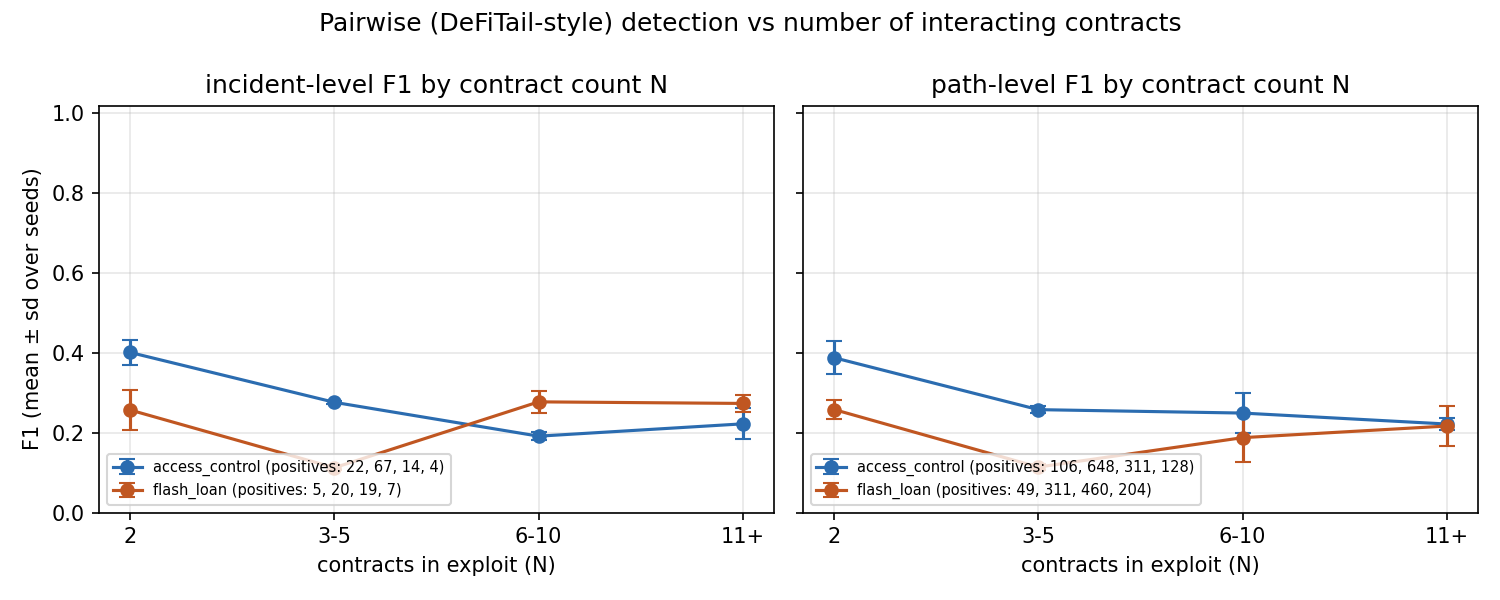

In [6]:
plot_degradation(agg, RESULTS / "degradation.png")
from IPython.display import Image; Image(RESULTS / "degradation.png")

## Reference baseline: logistic regression on bag of opcodes
Same folds and seeds. If it degrades the same way, the effect comes from the pairwise data view, not from the BERT/GCN model.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
if (RESULTS / "baseline_logreg_oof.csv").exists():
    base = pd.read_csv(RESULTS / "baseline_logreg_oof.csv", dtype={"bucket": str})
else:
    Xb = TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(df.opcodes)
    inc_b = df.groupby("event_id").agg(bucket=("bucket", "first"), **{t: (t, "max") for t in TASKS}).reset_index()
    strat = inc_b.bucket.astype(str) + "_" + inc_b[TASKS].astype(str).agg("".join, axis=1)
    strat = strat.where(strat.map(strat.value_counts()) >= CFG["folds"], inc_b.bucket.astype(str))
    parts = []
    for seed in CFG["seeds"]:
        for itr, ite in StratifiedKFold(CFG["folds"], shuffle=True, random_state=seed).split(inc_b, strat):
            tr = np.where(df.event_id.isin(set(inc_b.event_id.iloc[itr])))[0]; te = np.where(df.event_id.isin(set(inc_b.event_id.iloc[ite])))[0]
            part = df.iloc[te][["event_id", "bucket", *TASKS]].copy(); part["seed"] = seed
            for t in TASKS:
                m = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xb[tr], df[t].values[tr])
                part[f"p_{t}"] = m.predict_proba(Xb[te])[:, 1]
            parts.append(part)
    base = pd.concat(parts); base.to_csv(RESULTS / "baseline_logreg_oof.csv", index=False)
_, base_agg = summarize(base); base_agg.to_csv(RESULTS / "baseline_logreg_metrics_summary.csv", index=False)

## Main result: threshold-free incident-level AUC by bucket (95% bootstrap CI)
F1 at a fixed 0.5 threshold depends on each bucket's share of positives, which differs a lot across buckets (e.g. access
control: 23% at N=2 vs 9% at 11+). ROC-AUC does not, so it is the fair comparison across N.

,task,model,bucket,n,positives,auc,ci_lo,ci_hi
0,access_control,BERT+GCN (DeFiTail-style),all,704,107,0.587,0.526,0.650
1,access_control,BERT+GCN (DeFiTail-style),2,94,22,0.645,0.510,0.778
2,access_control,BERT+GCN (DeFiTail-style),3-5,431,67,0.567,0.494,0.639
3,access_control,BERT+GCN (DeFiTail-style),6-10,135,14,0.603,0.405,0.800
4,access_control,BERT+GCN (DeFiTail-style),11+,44,4,0.756,0.359,0.979
5,access_control,Logistic regression (bag of opcodes),all,704,107,0.661,0.603,0.715
6,access_control,Logistic regression (bag of opcodes),2,94,22,0.688,0.561,0.805
7,access_control,Logistic regression (bag of opcodes),3-5,431,67,0.623,0.549,0.695
8,access_control,Logistic regression (bag of opcodes),6-10,135,14,0.700,0.522,0.855
9,access_control,Logistic regression (bag of opcodes),11+,44,4,0.938,0.837,1.000


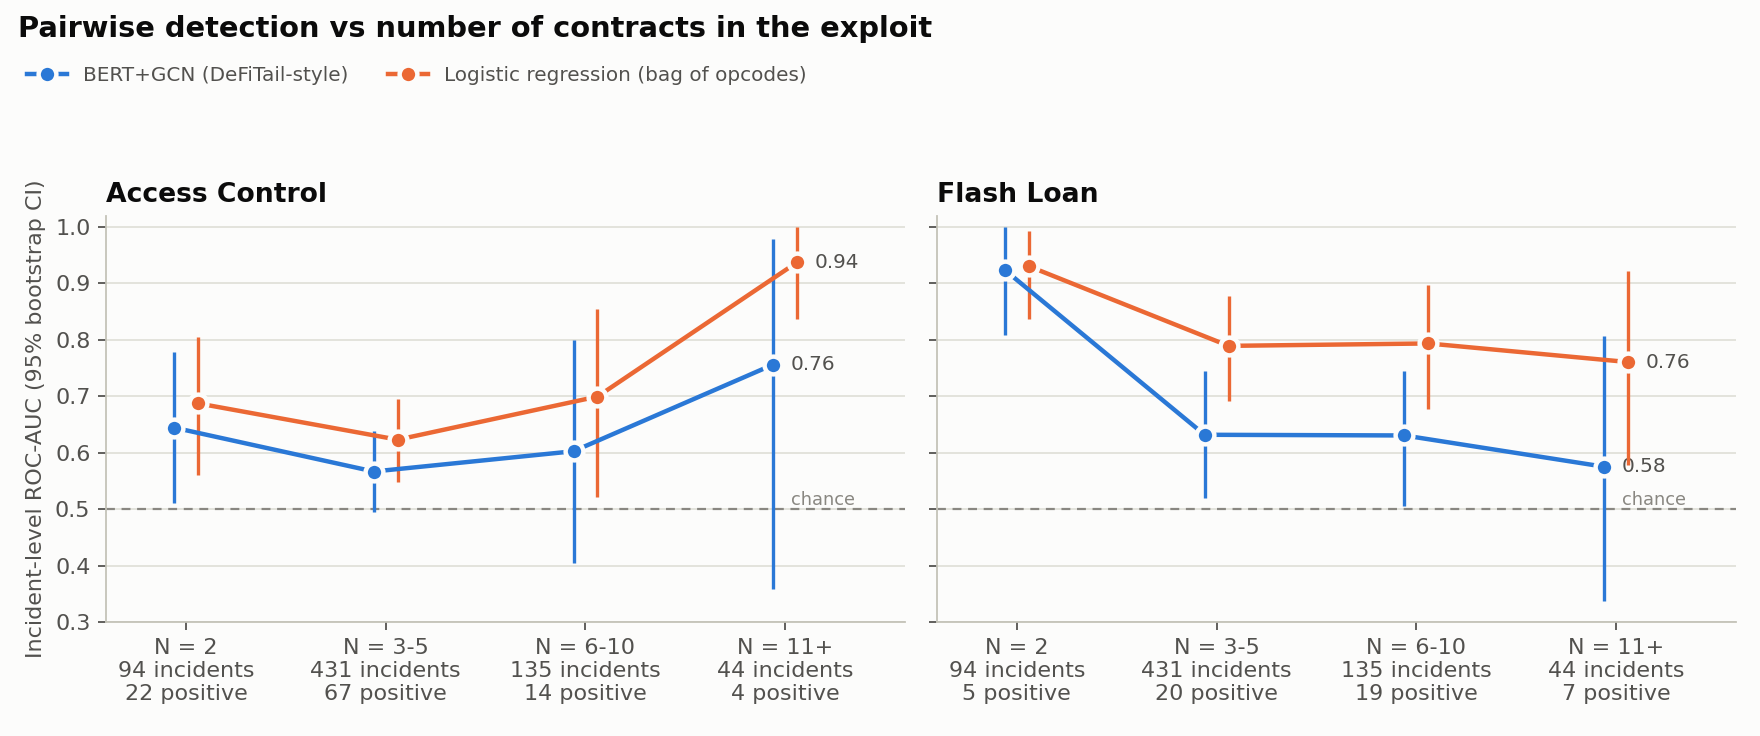

In [8]:
import matplotlib
import matplotlib.pyplot as plt


TASKS, BUCKETS = ["access_control", "flash_loan"], ["2", "3-5", "6-10", "11+"]
INK, INK2, MUTED, GRID, BASE, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = {"BERT+GCN (DeFiTail-style)": "#2a78d6", "Logistic regression (bag of opcodes)": "#eb6834"}


def incident_scores(oof, t, col):
    """One score per incident: max over its paths within a seed, then mean over seeds."""
    s = oof.groupby(["seed", "event_id"]).agg(bucket=("bucket", "first"), y=(t, "max"), p=(col, "max")).reset_index()
    return s.groupby("event_id").agg(bucket=("bucket", "first"), y=("y", "first"), p=("p", "mean"))


def auc_ci(y, p, rng, n=2000):
    boots = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i): boots.append(roc_auc_score(y[i], p[i]))
    return roc_auc_score(y, p), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


def make(oof, base, out_png, out_csv):
    rng = np.random.default_rng(0)
    rows = []
    for t in TASKS:
        for name, (df, col) in {"BERT+GCN (DeFiTail-style)": (oof, f"p_{t}"),
                                "Logistic regression (bag of opcodes)": (base, f"p_{t}")}.items():
            inc = incident_scores(df, t, col)
            for b in ["all"] + BUCKETS:
                s = inc if b == "all" else inc[inc.bucket == b]
                a, lo, hi = auc_ci(s.y.values, s.p.values, rng)
                rows.append(dict(task=t, model=name, bucket=b, n=len(s), positives=int(s.y.sum()), auc=a, ci_lo=lo, ci_hi=hi))
    tab = pd.DataFrame(rows); tab.to_csv(out_csv, index=False)

    plt.rcParams.update({"font.size": 10, "axes.edgecolor": BASE, "axes.labelcolor": INK2, "xtick.color": INK2,
                         "ytick.color": INK2, "axes.titlecolor": INK, "figure.facecolor": SURF, "axes.facecolor": SURF})
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
    x = np.arange(len(BUCKETS))
    for ax, t in zip(axes, TASKS):
        for k, (name, color) in enumerate(SERIES.items()):
            s = tab[(tab.task == t) & (tab.model == name)].set_index("bucket").reindex(BUCKETS)
            xs = x + (k - 0.5) * 0.12
            ax.errorbar(xs, s.auc, yerr=[s.auc - s.ci_lo, s.ci_hi - s.auc], color=color, lw=2, marker="o", ms=8,
                        mec=SURF, mew=2, capsize=0, elinewidth=1.5, label=name, zorder=3)
            ax.annotate(f"{s.auc.iloc[-1]:.2f}", (xs[-1], s.auc.iloc[-1]), xytext=(8, 0), textcoords="offset points",
                        va="center", fontsize=9, color=INK2)
        pos = tab[(tab.task == t) & (tab.model == list(SERIES)[0])].set_index("bucket").reindex(BUCKETS)
        ax.set_xticks(x, [f"N = {b}\n{int(r.n)} incidents\n{int(r.positives)} positive" for b, r in pos.iterrows()])
        ax.axhline(0.5, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=1)
        ax.text(x[-1] + 0.35, 0.5, "chance", color=MUTED, fontsize=8, va="bottom", ha="right")
        ax.set_title(t.replace("_", " ").title(), loc="left", fontsize=12, fontweight="bold")
        ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
        ax.set_xlim(-0.4, len(BUCKETS) - 0.4); ax.set_ylim(0.3, 1.02)
    axes[0].set_ylabel("Incident-level ROC-AUC (95% bootstrap CI)")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper left", ncol=2, frameon=False, fontsize=9, labelcolor=INK2, bbox_to_anchor=(0.005, 0.935))
    fig.suptitle("Pairwise detection vs number of contracts in the exploit", x=0.01, ha="left", fontsize=13,
                 fontweight="bold", color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(out_png, dpi=160); plt.close(fig)
    return tab


auc_tab = make(oof, base, RESULTS / "degradation_auc.png", RESULTS / "auc_by_bucket_ci.csv")
display(auc_tab.round(3))
Image(RESULTS / "degradation_auc.png")

## Is N=2 different from N>=3? Bootstrap CI of the AUC difference

In [9]:
rng = np.random.default_rng(1); rows = []
for t in TASKS:
    for name, (d_, col) in {"BERT+GCN": (oof, f"p_{t}"), "LogReg": (base, f"p_{t}")}.items():
        inc_s = incident_scores(d_, t, col); a, b = inc_s[inc_s.bucket == "2"], inc_s[inc_s.bucket != "2"]
        diff0 = roc_auc_score(a.y, a.p) - roc_auc_score(b.y, b.p); ds = []
        for _ in range(4000):
            ia, ib = rng.integers(0, len(a), len(a)), rng.integers(0, len(b), len(b))
            if 0 < a.y.values[ia].sum() < len(ia):
                ds.append(roc_auc_score(a.y.values[ia], a.p.values[ia]) - roc_auc_score(b.y.values[ib], b.p.values[ib]))
        ds = np.array(ds)
        rows.append(dict(task=t, model=name, auc_N2=roc_auc_score(a.y, a.p), auc_N3plus=roc_auc_score(b.y, b.p), diff=diff0,
                         ci_lo=np.percentile(ds, 2.5), ci_hi=np.percentile(ds, 97.5)))
diff_tab = pd.DataFrame(rows); diff_tab.to_csv(RESULTS / "auc_difference_N2_vs_N3plus.csv", index=False); diff_tab.round(3)

,task,model,auc_N2,auc_N3plus,diff,ci_lo,ci_hi
0,access_control,BERT+GCN,0.645,0.579,0.065,-0.083,0.214
1,access_control,LogReg,0.688,0.655,0.033,-0.109,0.170
2,flash_loan,BERT+GCN,0.924,0.648,0.276,0.146,0.385
3,flash_loan,LogReg,0.930,0.799,0.131,0.024,0.226
